# Обнаружение сетевых атак по признакам сетевых потоков: разведочный анализ данных CIC-IDS2017

**Дисциплина:** «Программные инструменты анализа данных в задачах информационной безопасности»

**Тема работы:** разведочный анализ размеченных сетевых потоков для задачи обнаружения атак.




## 1. Введение

Настоящая работа посвящена разведочному анализу (EDA) набора данных CIC-IDS2017, содержащего размеченные записи о сетевых потоках. Цель анализа — оценить пригодность признаков сетевых потоков для задачи бинарной классификации «легитимный трафик / атака», выявить особенности данных (пропуски, дубликаты, дисбаланс классов, выбросы) и сформулировать обоснованные рекомендации по предобработке перед этапом построения модели машинного обучения.

Работа носит аналитический характер: модель классификации в ней не обучается, а исследуются свойства данных, значимые для последующего моделирования.

## 2. Бизнес-постановка задачи

В корпоративных сетях объём трафика постоянно растёт, и ручной анализ всех соединений аналитиками центра мониторинга информационной безопасности (SOC) не является практически осуществимым. Одним из инструментов снижения нагрузки на аналитиков является автоматическая система обнаружения вторжений (IDS), которая выделяет из общего потока соединения, требующие приоритетного рассмотрения.

Задача настоящей работы — исследовать статистические свойства сетевых потоков и определить, в какой степени по доступным признакам можно отделить нормальную сетевую активность от активности, связанной с атаками. Полученные выводы предназначены для обоснования дальнейшей разработки компонента обнаружения, который может использоваться как часть IDS.

Практическая ценность такого компонента определяется двумя факторами:
- **полнота обнаружения** — способность фиксировать как можно большую долю реальных атак;
- **точность срабатываний** — доля ложных тревог, которые увеличивают нагрузку на аналитика.

Оба фактора учитываются при выборе метрик качества (раздел 4).

## 3. Постановка задачи машинного обучения

**Тип задачи:** бинарная классификация.

**Единица наблюдения:** один сетевой поток (flow), описываемый набором признаков, рассчитанных по агрегированным характеристикам соединения (длительность, число пакетов и байт в прямом и обратном направлениях, статистики межпакетных интервалов и т. п.).

**Целевая переменная:**
- класс `BENIGN` — Легитимный трафик;
- класс `Attack` — трафик, помеченный в исходном наборе как одна из разновидностей атак (объединение всех не-`BENIGN` меток).

Объединение меток атак в один класс является осознанным упрощением: оно позволяет на первом этапе оценить принципиальную разделимость нормального и аномального трафика. Различение конкретных типов атак — задача последующего, более детального анализа.

**Входные данные:** признаки сетевых потоков, рассчитанные средствами CICFlowMeter и предоставленные в составе набора CIC-IDS2017.

## 4. Обоснование метрик качества

Выбор метрик обусловлен характером задачи обнаружения атак и ожидаемым дисбалансом классов.

**Recall для класса «атака»** — доля обнаруженных атак среди всех реальных атак. Пропущенная атака означает потенциальный ущерб, поэтому recall является ключевой метрикой. Снижение recall напрямую увеличивает риск того, что часть вторжений останется без реакции.

**Precision для класса «атака»** — доля истинных атак среди всех срабатываний системы. Низкий precision приводит к большому числу ложных тревог, что ведёт к усталости аналитиков и снижению доверия к системе.

**F1-score** — гармоническое среднее precision и recall, удобное для сводной оценки баланса между полнотой и точностью.

**PR-AUC (Average Precision)** — площадь под кривой precision–recall. При сильном дисбалансе классов (что ожидается в трафике, где атаки в большинстве сценариев составляют меньшинство) эта метрика информативнее ROC-AUC, поскольку отражает поведение классификатора именно на редком классе.

**Accuracy не используется как основная метрика.** При существенном дисбалансе модель, предсказывающая доминирующий класс, может демонстрировать высокую accuracy, при этом не обнаруживая атак вовсе. Поэтому accuracy приводится лишь как справочная величина.

Конкретный рабочий порог классификатора и допустимое соотношение между пропущенными атаками и ложными тревогами определяются требованиями эксплуатирующей организации и в данной работе не фиксируются.

## 5. Описание набора данных CIC-IDS2017

CIC-IDS2017 — публичный набор данных, подготовленный Canadian Institute for Cybersecurity (University of New Brunswick) и предназначенный для исследования и сравнительной оценки систем обнаружения вторжений. Официальная страница набора: <https://www.unb.ca/cic/datasets/ids-2017.html>.

Набор содержит трафик, собранный в тестовой сети в течение пяти рабочих дней. Каждый день соответствует определённому сценарию: понедельник — только легитимный трафик, остальные дни — комбинация нормальной активности и различных типов атак (Brute Force, DoS/DDoS, Web-атаки, инфильтрация, ботнет и др.).

Признаки потоков рассчитаны инструментом CICFlowMeter и включают, в частности:
- длительность потока (`Flow Duration`);
- количество и суммарный объём пакетов в прямом и обратном направлениях;
- интенсивность трафика (`Flow Bytes/s`, `Flow Packets/s`);
- статистики межпакетных интервалов (среднее, стандартное отклонение, минимум, максимум);
- флаги TCP и ряд дополнительных характеристик.

Целевая метка хранится в столбце `Label` и принимает значение `BENIGN` для нормального трафика и название типа атаки — для вредоносного.

В данной работе используется предобработанная версия набора: файлы в формате Parquet, разбитые по дням и сценариям атак. Формат Parquet выбран из соображений компактности и скорости чтения.

**Ограничения набора, значимые для интерпретации результатов:**
- трафик собран в лабораторной тестовой сети и может отличаться от трафика реальных корпоративных сетей;
- распределение типов атак между днями неравномерно;
- в исходных данных присутствуют повторяющиеся записи и артефакты вычисления признаков (пропуски, бесконечные значения), требующие обработки.

## 6. Импорт библиотек

Используются стандартные библиотеки анализа данных: `pandas` и `numpy` для работы с таблицами и вычислений, `matplotlib` и `seaborn` для визуализации.

In [18]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

pd.set_option('display.float_format', lambda x: '%.2f' % x)

RANDOM_STATE = 42

FEATURE_TRANSLATIONS = {
    "Protocol": "Протокол",
    "Flow Duration": "Длительность потока",
    "Total Fwd Packets": "Всего пакетов (вперед)",
    "Total Backward Packets": "Всего пакетов (назад)",
    "Fwd Packets Length Total": "Общий размер пакетов (вперед)",
    "Bwd Packets Length Total": "Общий размер пакетов (назад)",
    "Fwd Packet Length Max": "Макс. размер пакета (вперед)",
    "Fwd Packet Length Min": "Мин. размер пакета (вперед)",
    "Fwd Packet Length Mean": "Средний размер пакета (вперед)",
    "Fwd Packet Length Std": "Ст. откл. размера пакета (вперед)",
    "Bwd Packet Length Max": "Макс. размер пакета (назад)",
    "Bwd Packet Length Min": "Мин. размер пакета (назад)",
    "Bwd Packet Length Mean": "Средний размер пакета (назад)",
    "Bwd Packet Length Std": "Ст. откл. размера пакета (назад)",
    "Flow Bytes/s": "Скорость потока (байт/с)",
    "Flow Packets/s": "Скорость потока (пакетов/с)",
    "Flow IAT Mean": "Средний межпакетный интервал",
    "Flow IAT Std": "Ст. откл. межпакетного интервала",
    "Flow IAT Max": "Макс. межпакетный интервал",
    "Flow IAT Min": "Мин. межпакетный интервал",
    "Fwd IAT Total": "Суммарный интервал (вперед)",
    "Fwd IAT Mean": "Средний интервал (вперед)",
    "Fwd IAT Std": "Ст. откл. интервала (вперед)",
    "Fwd IAT Max": "Макс. интервал (вперед)",
    "Fwd IAT Min": "Мин. интервал (вперед)",
    "Bwd IAT Total": "Суммарный интервал (назад)",
    "Bwd IAT Mean": "Средний интервал (назад)",
    "Bwd IAT Std": "Ст. откл. интервала (назад)",
    "Bwd IAT Max": "Макс. интервал (назад)",
    "Bwd IAT Min": "Мин. интервал (назад)",
    "Fwd PSH Flags": "Флаги PSH (вперед)",
    "Bwd PSH Flags": "Флаги PSH (назад)",
    "Fwd URG Flags": "Флаги URG (вперед)",
    "Bwd URG Flags": "Флаги URG (назад)",
    "Fwd Header Length": "Длина заголовка (вперед)",
    "Bwd Header Length": "Длина заголовка (назад)",
    "Fwd Packets/s": "Пакетов/с (вперед)",
    "Bwd Packets/s": "Пакетов/с (назад)",
    "Packet Length Min": "Мин. размер пакета",
    "Packet Length Max": "Макс. размер пакета",
    "Packet Length Mean": "Средний размер пакета",
    "Packet Length Std": "Ст. откл. размера пакета",
    "Packet Length Variance": "Дисперсия размера пакета",
    "FIN Flag Count": "Кол-во флагов FIN",
    "SYN Flag Count": "Кол-во флагов SYN",
    "RST Flag Count": "Кол-во флагов RST",
    "PSH Flag Count": "Кол-во флагов PSH",
    "ACK Flag Count": "Кол-во флагов ACK",
    "URG Flag Count": "Кол-во флагов URG",
    "CWE Flag Count": "Кол-во флагов CWE",
    "ECE Flag Count": "Кол-во флагов ECE",
    "Down/Up Ratio": "Отношение Down/Up",
    "Avg Packet Size": "Средний размер пакета",
    "Avg Fwd Segment Size": "Средний размер сегмента (вперед)",
    "Avg Bwd Segment Size": "Средний размер сегмента (назад)",
    "Fwd Avg Bytes/Bulk": "Ср. байт/пакет (вперед)",
    "Fwd Avg Packets/Bulk": "Ср. пакетов/блок (вперед)",
    "Fwd Avg Bulk Rate": "Ср. скорость блока (вперед)",
    "Bwd Avg Bytes/Bulk": "Ср. байт/пакет (назад)",
    "Bwd Avg Packets/Bulk": "Ср. пакетов/блок (назад)",
    "Bwd Avg Bulk Rate": "Ср. скорость блока (назад)",
    "Subflow Fwd Packets": "Пакетов подпотока (вперед)",
    "Subflow Fwd Bytes": "Байт подпотока (вперед)",
    "Subflow Bwd Packets": "Пакетов подпотока (назад)",
    "Subflow Bwd Bytes": "Байт подпотока (назад)",
    "Init Fwd Win Bytes": "Нач. окно (вперед)",
    "Init Bwd Win Bytes": "Нач. окно (назад)",
    "Fwd Act Data Packets": "Активных пакетов данных (вперед)",
    "Fwd Seg Size Min": "Мин. размер сегмента (вперед)",
    "Active Mean": "Среднее время активности",
    "Active Std": "Ст. откл. времени активности",
    "Active Max": "Макс. время активности",
    "Active Min": "Мин. время активности",
    "Idle Mean": "Среднее время простоя",
    "Idle Std": "Ст. откл. времени простоя",
    "Idle Max": "Макс. время простоя",
    "Idle Min": "Мин. время простоя",
    "Label": "Метка класса",
    "source_file": "Исходный файл",
    "target_binary": "Бинарный класс",
    "target_ru": "Класс (рус.)"
}

## 7. Загрузка данных

Параметр `DATA_DIR` задаёт каталог с Parquet-файлами. Режим `LOAD_MODE` определяет, загружаются ли все найденные файлы или только выбранные сценарии (полезно при ограниченных ресурсах памяти). Служебный столбец `source_file` фиксирует происхождение записи и используется только для анализа, но не как признак модели.

In [3]:
DATA_DIR = Path.cwd() / "datasets"

LOAD_MODE = "all"
SELECTED_FILES = [
    "Benign-Monday-no-metadata.parquet",
    "DDoS-Friday-no-metadata.parquet",
]

parquet_files = sorted(DATA_DIR.glob("*.parquet"))
if not parquet_files:
    raise FileNotFoundError(
        f"По пути {DATA_DIR.resolve()} не обнаружены файлы"
    )

print(f"Обнаружено Parquet-файлов: {len(parquet_files)}")
for path in parquet_files:
    print(f"- {path.name} ({path.stat().st_size / (1024**2):.1f} MiB)")

if LOAD_MODE == "all":
    files_to_load = parquet_files
elif LOAD_MODE == "selected":
    missing_files = [name for name in SELECTED_FILES if not (DATA_DIR / name).exists()]
    if missing_files:
        raise FileNotFoundError(f"Не найдены выбранные файлы: {missing_files}")
    files_to_load = [DATA_DIR / name for name in SELECTED_FILES]
else:
    raise ValueError('Параметр LOAD_MODE должен принимать значение "all" или "selected".')

frames = []
for path in files_to_load:
    part = pd.read_parquet(path)
    part.columns = part.columns.astype(str).str.strip()
    part["source_file"] = path.name
    frames.append(part)
    print(f"Загружен {path.name}: {len(part):,} строк × {part.shape[1] - 1} столбцов")

df = pd.concat(frames, ignore_index=True, sort=False)
df.columns = df.columns.astype(str).str.strip()

print(f"\nИтоговый размер объединённой таблицы: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())

Обнаружено Parquet-файлов: 8
- Benign-Monday-no-metadata.parquet (54.1 MiB)
- Botnet-Friday-no-metadata.parquet (18.9 MiB)
- Bruteforce-Tuesday-no-metadata.parquet (44.0 MiB)
- DDoS-Friday-no-metadata.parquet (24.1 MiB)
- DoS-Wednesday-no-metadata.parquet (65.0 MiB)
- Infiltration-Thursday-no-metadata.parquet (22.1 MiB)
- Portscan-Friday-no-metadata.parquet (13.0 MiB)
- WebAttacks-Thursday-no-metadata.parquet (16.8 MiB)
Загружен Benign-Monday-no-metadata.parquet: 458,831 строк × 78 столбцов
Загружен Botnet-Friday-no-metadata.parquet: 176,038 строк × 78 столбцов
Загружен Bruteforce-Tuesday-no-metadata.parquet: 389,714 строк × 78 столбцов
Загружен DDoS-Friday-no-metadata.parquet: 221,264 строк × 78 столбцов
Загружен DoS-Wednesday-no-metadata.parquet: 584,991 строк × 78 столбцов
Загружен Infiltration-Thursday-no-metadata.parquet: 207,630 строк × 78 столбцов
Загружен Portscan-Friday-no-metadata.parquet: 119,522 строк × 78 столбцов
Загружен WebAttacks-Thursday-no-metadata.parquet: 155,820 с

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,6,4,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4,4,4,4.0,0.000000,4,4,0,0.000000,0.000000,0,0,0,0,0,0,40,0,5.000000e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
1,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
2,6,3,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3,3,3,3.0,0.000000,3,3,0,0.000000,0.000000,0,0,0,0,0,0,40,0,6.666667e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
3,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
4,6,609,7,4,484,414,233,0,69.14286,111.967896,207,0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381,2,609,101.5,177.089523,460,2,467,155.666672,263.560883,460,3,0,0,0,0,164,104,1.149425e+04,6568.144531,0,233,74.833336,107.527443,11562.151367,0,0,0,1,0,0,0,0,0,81.63636,69.14286,103.5,0,0,0,0,0,0,7,484,4,414,8192,2053,5,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet


## 8. Структура и типы данных

На данном шаге проверяются размер таблицы, состав столбцов и распределение типов. Корректное определение числовых признаков необходимо для последующего анализа распределений и корреляций.

In [19]:
print("Размер таблицы:", df.shape)

print("\nРаспределение типов данных:")
dtypes_counts = df.dtypes.value_counts().rename_axis("Тип данных").to_frame("Число столбцов")
display(dtypes_counts)

print("\nПеречень столбцов:")
columns_df = pd.DataFrame({
    "Столбец (оригинал)": df.columns,
    "Тип данных": df.dtypes.astype(str).values
})

columns_df["Столбец (перевод)"] = columns_df["Столбец (оригинал)"].map(FEATURE_TRANSLATIONS).fillna(columns_df["Столбец (оригинал)"])
display(columns_df[["Столбец (оригинал)", "Столбец (перевод)", "Тип данных"]])

Размер таблицы: (2313810, 80)

Распределение типов данных:


,Число столбцов
Тип данных,
int32,26
float32,22
int8,19
int16,7
float64,2
str,2
int64,1
string,1



Перечень столбцов:


,Столбец (оригинал),Столбец (перевод),Тип данных
0,Protocol,Протокол,int8
1,Flow Duration,Длительность потока,int32
2,Total Fwd Packets,Всего пакетов (вперед),int32
3,Total Backward Packets,Всего пакетов (назад),int32
4,Fwd Packets Length Total,Общий размер пакетов (вперед),int32
5,Bwd Packets Length Total,Общий размер пакетов (назад),int32
6,Fwd Packet Length Max,Макс. размер пакета (вперед),int16
7,Fwd Packet Length Min,Мин. размер пакета (вперед),int16
8,Fwd Packet Length Mean,Средний размер пакета (вперед),float32
9,Fwd Packet Length Std,Ст. откл. размера пакета (вперед),float32


## 9. Целевой столбец

Целевой столбец в наборе CIC-IDS2017 называется `Label`. Поиск выполняется без учёта регистра, поскольку в разных выгрузках встречаются варианты написания. Пробелы по краям значений меток удаляются — в исходных файлах они присутствуют и без нормализации могут приводить к появлению фиктивных классов.

In [33]:
label_candidates = [c for c in df.columns if c.lower() == "label"]
label_candidates = [c for c in df.columns if c.lower() == "label"]
if not label_candidates:
    raise ValueError("Столбец Label не найден.")

LABEL_COL = label_candidates[0]
df[LABEL_COL] = df[LABEL_COL].astype("string").str.strip()

print("Целевой столбец:", FEATURE_TRANSLATIONS.get(LABEL_COL, LABEL_COL))
labels_normalized = df[LABEL_COL].astype("string").str.strip()
is_benign = labels_normalized.str.upper().eq("BENIGN")

df["target_binary"] = np.where(is_benign, "BENIGN", "Attack")
df.loc[labels_normalized.isna(), "target_binary"] = pd.NA

df["target_ru"] = df["target_binary"].map({"BENIGN": "Легитимный", "Attack": "Атака"})

label_counts = df[LABEL_COL].value_counts(dropna=False).to_frame("Количество")
label_counts.index.name = "Исходная метка"
label_counts.index = label_counts.index.map(lambda x: "Легитимный (Benign)" if str(x).strip().upper() == "BENIGN" else x)
display(label_counts.head(20))

Целевой столбец: Метка класса


,Количество
Исходная метка,
Легитимный (Benign),1977318
DoS Hulk,172846
DDoS,128014
DoS GoldenEye,10286
FTP-Patator,5931
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219
PortScan,1956


## 10. Пропущенные и бесконечные значения

Пропуски (`NaN`) и бесконечности (`inf`) искажают статистики и препятствуют корректному обучению моделей. Бесконечные значения типичны для производных признаков, рассчитываемых как отношение с возможным нулевым знаменателем (например, интенсивность `Flow Bytes/s` при нулевой длительности потока).

In [20]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({"Кол-во пропусков": missing, "Доля, %": missing_pct})
missing_report.index = missing_report.index.map(lambda x: FEATURE_TRANSLATIONS.get(x, x))
missing_report.index.name = "Признак (перевод)"
print("Столбцы с пропущенными значениями:")
display(missing_report[missing_report["Кол-во пропусков"] > 0].head(30))

numeric_cols_initial = df.select_dtypes(include=np.number).columns
if len(numeric_cols_initial):
    inf_counts = pd.Series(
        np.isinf(df[numeric_cols_initial].to_numpy()).sum(axis=0),
        index=numeric_cols_initial
    ).sort_values(ascending=False)
    inf_counts.index = inf_counts.index.map(lambda x: FEATURE_TRANSLATIONS.get(x, x))
    inf_counts.index.name = "Признак (перевод)"
    print("Столбцы с бесконечными значениями:")
    display(inf_counts[inf_counts > 0].to_frame("Кол-во бесконечностей").head(30))

Столбцы с пропущенными значениями:


,Кол-во пропусков,"Доля, %"
Признак (перевод),,


Столбцы с бесконечными значениями:


,Кол-во бесконечностей
Признак (перевод),


**Комментарий к результатам.** В объединённом наборе пропущенные и бесконечные значения в числовых признаках отсутствуют. Однако при проверке подозрительных значений (раздел 17) обнаружены отрицательные значения в ряде признаков: Flow Duration (88 строк), а также в Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Max, Fwd IAT Min, Fwd Header Length, Bwd Header Length, Fwd Seg Size Min, Init Fwd Win Bytes и Init Bwd Win Bytes. Это артефакты расчёта CICFlowMeter и особенности интерпретации TCP-флагов (значение -1 в Init ... Win Bytes означает отсутствие соответствующего поля), а не ошибки формата. Автоматическая замена отрицательных значений нулями недопустима — это исказит распределения; на этапе предобработки целесообразно либо отфильтровать такие строки (для Flow Duration < 0 — 88 записей), либо обрабатывать признаки по отдельности с учётом их семантики.

## 11. Дубликаты

Полные дубликаты строк могут возникать при объединении файлов или при повторной выгрузке данных. Если одинаковые записи попадают и в обучающую, и в тестовую выборки, оценка качества модели оказывается завышенной. При этом совпадение всех признаков не всегда означает ошибочность записи — в сетевом трафике повторяющиеся потоки возможны. Решение об удалении принимается с учётом происхождения данных.

In [8]:
duplicate_count = int(df.drop(columns=["source_file"], errors="ignore").duplicated().sum())
print(f"Полных дубликатов строк (без учёта source_file): {duplicate_count:,} "
      f"({duplicate_count / max(len(df), 1):.2%} от общего числа строк)")

Полных дубликатов строк (без учёта source_file): 82,004 (3.54% от общего числа строк)


## 12. Распределение целевой переменной

Все метки, кроме `BENIGN`, объединяются в класс `Attack`. Дополнительно анализируется распределение классов по исходным файлам: это позволяет оценить, насколько класс атаки связан с конкретным сценарием и как это может повлиять на разбиение данных при обучении.

,Количество
target_ru,
Легитимный,1977318
Атака,336492


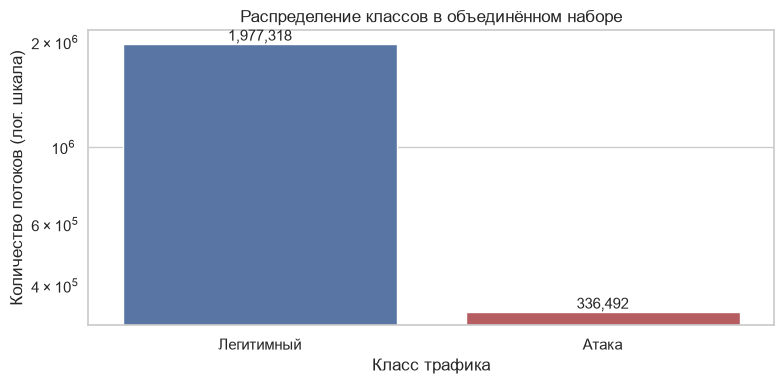

Доли классов (%):


,"Доля, %"
target_ru,
Легитимный,85.46
Атака,14.54


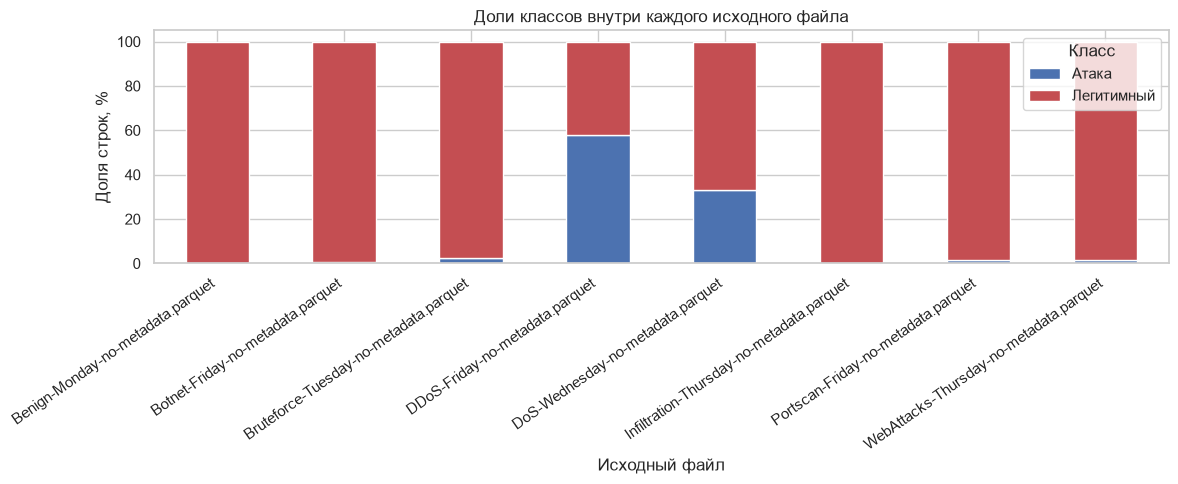

Абсолютные значения по файлам:


target_ru,Атака,Легитимный
source_file,,
Benign-Monday-no-metadata.parquet,0,458831
Botnet-Friday-no-metadata.parquet,1437,174601
Bruteforce-Tuesday-no-metadata.parquet,9150,380564
DDoS-Friday-no-metadata.parquet,128014,93250
DoS-Wednesday-no-metadata.parquet,193756,391235
Infiltration-Thursday-no-metadata.parquet,36,207594
Portscan-Friday-no-metadata.parquet,1956,117566
WebAttacks-Thursday-no-metadata.parquet,2143,153677


In [34]:
class_counts = df["target_ru"].value_counts(dropna=False)
display(class_counts.to_frame("Количество"))

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x="target_ru", order=["Легитимный", "Атака"], palette=["#4c72b0", "#c44e52"])
ax.set_title("Распределение классов в объединённом наборе")
ax.set_xlabel("Класс трафика")
ax.set_ylabel("Количество потоков (лог. шкала)")
ax.set_yscale("log")
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.show()

print("Доли классов (%):")
display((df["target_ru"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("Доля, %"))

if "source_file" in df.columns:
    source_class = pd.crosstab(df["source_file"], df["target_ru"], normalize="index") * 100
    ax = source_class.plot(kind="bar", stacked=True, figsize=(12, 5), color=["#4c72b0", "#c44e52"])
    ax.set_title("Доли классов внутри каждого исходного файла")
    ax.set_xlabel("Исходный файл")
    ax.set_ylabel("Доля строк, %")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Класс", labels=["Атака", "Легитимный"], loc='upper right')
    plt.tight_layout()
    plt.show()

    print("Абсолютные значения по файлам:")
    display(pd.crosstab(df["source_file"], df["target_ru"]))

**Комментарий к результатам.** Объединённый набор содержит 2 313 810 записей, из них BENIGN — 1 977 318 (85,46 %), Attack — 336 492 (14,54 %). Дисбаланс умеренный (соотношение ≈ 5,9 : 1), но достаточный, чтобы accuracy стала неинформативной: модель, предсказывающая всегда BENIGN, даст точность 85,5 %, не обнаружив ни одной атаки.
Распределение классов по файлам выявляет **выраженную сценарную структуру**:
- Benign-Monday содержит только нормальный трафик;
- DDoS-Friday — 128 014 атак при 93 250 нормальных потоков (57,9 % атак);
- DoS-Wednesday — 193 756 атак при 391 235 нормальных (33,1 %);
- Infiltration-Thursday — всего 36 атак на 207 594 нормальных потоков (< 0,02 %), т. е. практически не представлен в выборке;
- WebAttacks-Thursday — 2 143 атаки, из которых по исходным меткам видны Brute Force (1 470), XSS (652) и Sql Injection (21).

**Практическое следствие:** случайное разбиение на train/test приведёт к попаданию записей одного сценария в оба множества, что даст завышенную оценку качества из-за утечки. Рекомендуется разбиение с учётом source_file (group split) или временное разделение по дням. Кроме того, класс Attack крайне неоднороден: доля Infiltration составляет 0,01% от всех атак, поэтому recall по нему в общей бинарной метрике будет практически неразличим — при необходимости отдельного анализа редких атак следует строить многоклассовую или one-vs-rest модель.

## 13. Описательные статистики числовых признаков

Приведены среднее, стандартное отклонение, квартили, минимум и максимум. Для сетевого трафика характерны асимметричные распределения с длинными правыми хвостами, поэтому медиана и межквартильный размах часто информативнее среднего значения.

In [37]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_cols if c not in ["target_binary", "target_ru"]]

print(f"Числовых столбцов: {len(numeric_features)}")
if numeric_features:
    desc = df[numeric_features].describe(percentiles=[.01, .25, .5, .75, .99]).T
    desc = desc.round(2)
    desc.index = desc.index.map(lambda x: FEATURE_TRANSLATIONS.get(x, x))
    desc.index.name = "Признак (перевод)"
    desc.columns = ["Кол-во", "Среднее", "Ст. откл.", "Мин.", "1%", "25%", "50% (медиана)", "75%", "99%", "Макс."]
    desc = desc.drop(columns=["Кол-во"])
    display(desc)
else:
    print("Числовые признаки отсутствуют.")

Числовых столбцов: 77


,Среднее,Ст. откл.,Мин.,1%,25%,50% (медиана),75%,99%,Макс.
Признак (перевод),,,,,,,,,
Протокол,10.51,5.42,0.00,6.00,6.00,6.00,17.00,17.00,17.00
Длительность потока,18075748.27,36408233.47,-13.00,4.00,476.00,64783.00,5856947.75,118005108.56,119999998.00
Всего пакетов (вперед),11.08,829.19,1.00,1.00,2.00,2.00,6.00,55.00,219759.00
Всего пакетов (назад),12.55,1103.18,0.00,0.00,1.00,2.00,5.00,67.00,291922.00
Общий размер пакетов (вперед),666.40,11050.09,0.00,0.00,37.00,74.00,356.00,11607.00,12900000.00
Общий размер пакетов (назад),19769.76,2503141.35,0.00,0.00,26.00,183.00,2306.00,88302.64,655453030.00
Макс. размер пакета (вперед),250.63,785.51,0.00,0.00,20.00,43.00,274.00,4198.00,24820.00
Мин. размер пакета (вперед),21.42,63.34,0.00,0.00,0.00,6.00,39.00,80.00,2325.00
Средний размер пакета (вперед),68.81,202.30,0.00,0.00,8.67,39.56,54.00,1375.00,5940.86


## 14. Распределения ключевых признаков

Для визуализации выбраны признаки, наиболее показательные с точки зрения характеристики сетевого потока: длительность, количество пакетов и объём переданных данных в обоих направлениях, интенсивность. Логарифмическая шкала частоты позволяет увидеть форму распределения при наличии ярко выраженных экстремумов.

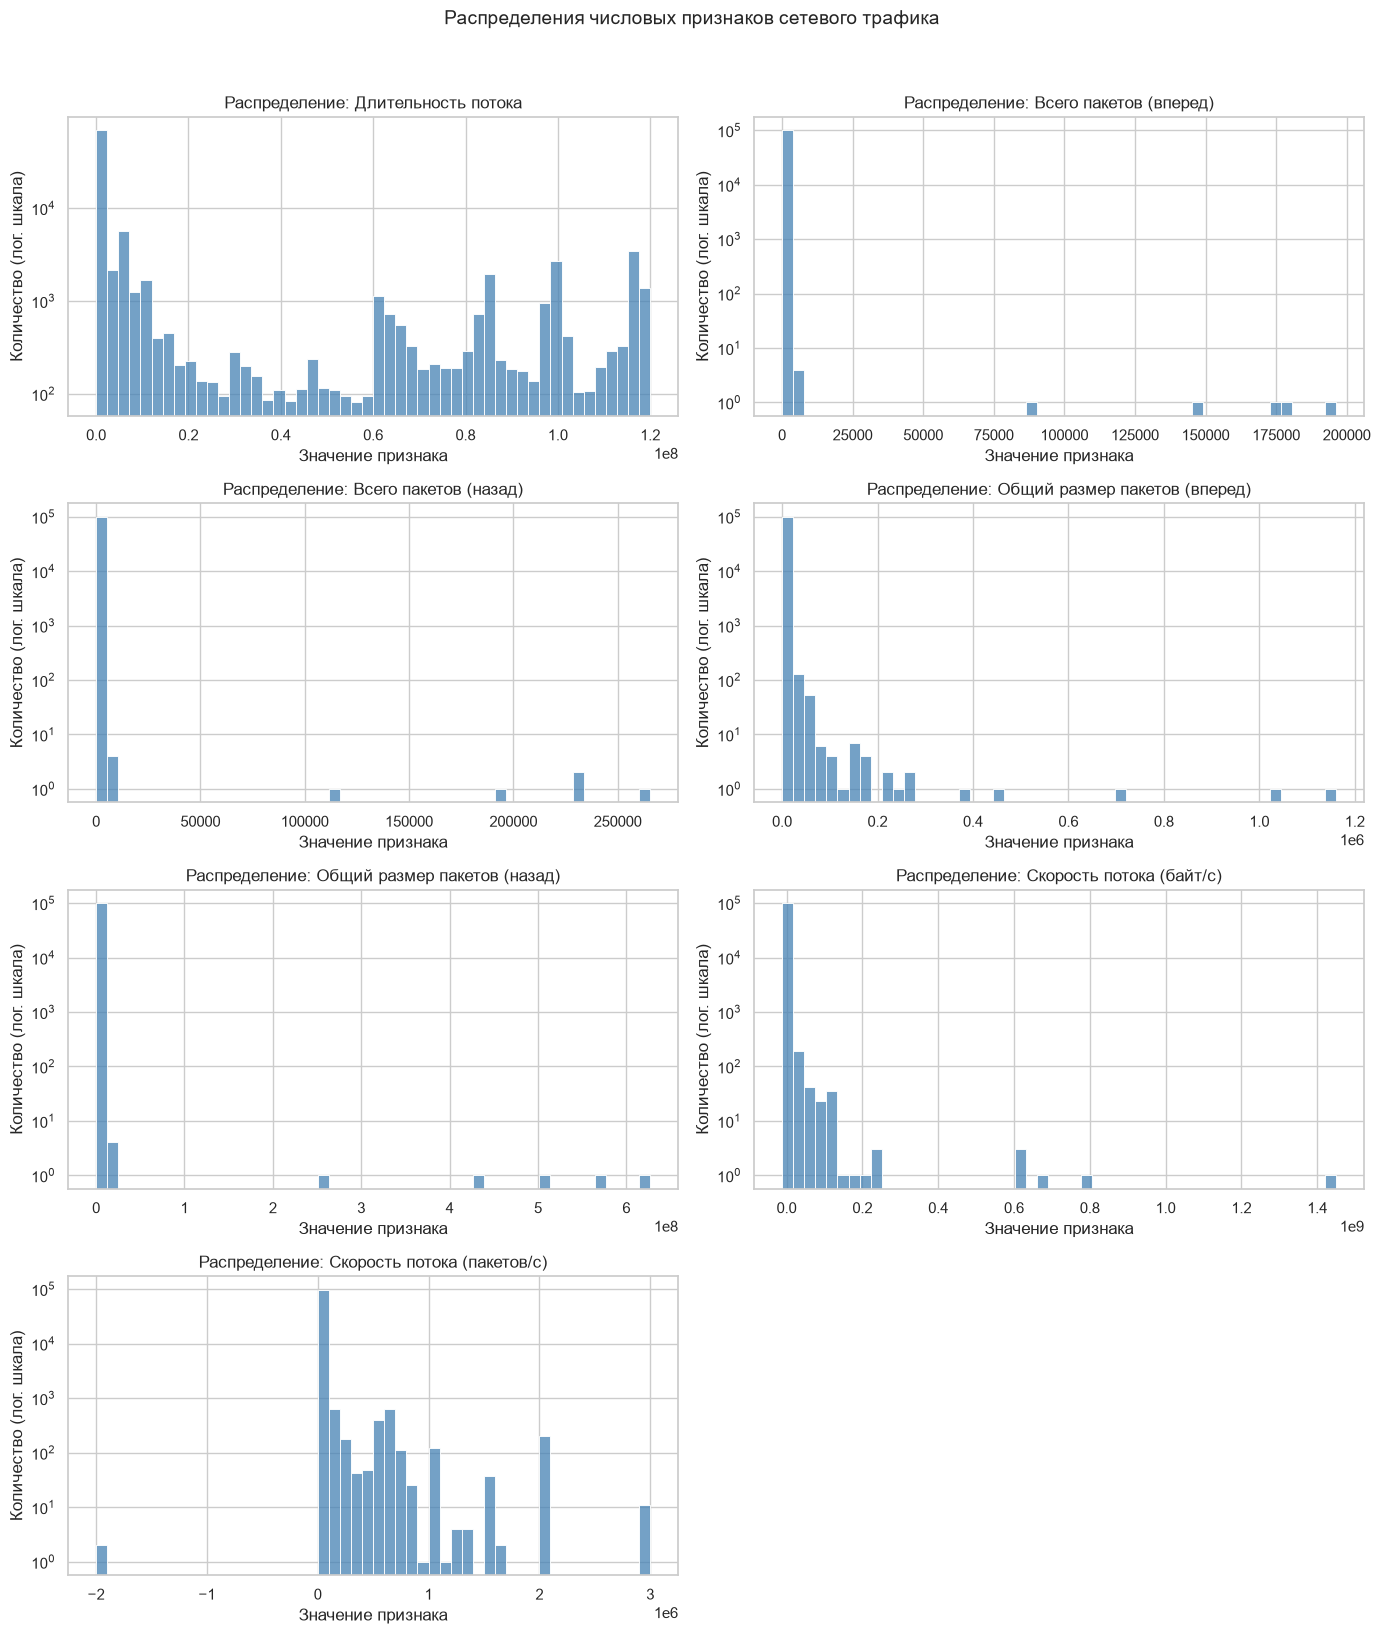

In [30]:
exact_features = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets", 
    "Fwd Packets Length Total", "Bwd Packets Length Total", 
    "Flow Bytes/s", "Flow Packets/s"
]
available_features = [c for c in exact_features if c in df.columns and pd.api.types.is_numeric_dtype(df[c])]

if available_features:
    ncols = 2
    nrows = int(np.ceil(len(available_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, available_features):
        values = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(values) > 100_000:
            values = values.sample(100_000, random_state=RANDOM_STATE)
        
        # Строим гистограмму
        sns.histplot(values, bins=50, ax=ax, color="steelblue")
        
        # Переводим название признака для заголовка
        col_ru = FEATURE_TRANSLATIONS.get(col, col)
        ax.set_title(f"Распределение: {col_ru}")
        ax.set_xlabel("Значение признака")
        ax.set_ylabel("Количество (лог. шкала)")
        ax.set_yscale("log")

    for ax in axes[len(available_features):]:
        ax.remove()

    plt.suptitle("Распределения числовых признаков сетевого трафика", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

**Комментарий к результатам.** Гистограммы подтверждают выводы описательных статистик.
- ***Flow Duration*** имеет бимодальное распределение: пик около 0 (короткие соединения) и второй, более широкий пик в районе 10⁸ (длительные сессии). Многомодальность указывает на неоднородность трафика — вероятно, смешение разных типов соединений (короткие запросы, длительные сессии, сканирования).
- ***Total Fwd Packets*** и ***Total Backward Packets*** практически полностью сосредоточены в области малых значений (1–10 пакетов), с очень редкими выбросами до 2 × 10⁵. Это означает, что большинство потоков в наборе — короткие, а небольшое число записей описывает длительные сессии с аномально большим числом пакетов. При обучении такие записи будут доминировать по вкладу в функцию потерь у моделей без регуляризации.
- ***Flow Bytes/s*** также имеет резко асимметричное распределение с длинным правым хвостом, причём присутствуют отрицательные значения (артефакт).

**Практическое следствие:** логарифмирование и/или клиппинг по 99-му процентилю целесообразны для всех перечисленных признаков; без этого модели, чувствительные к масштабу (логистическая регрессия, SVM, kNN), будут плохо сходиться, а деревья будут тратить глубину на редкие выбросы.

## 15. Сравнение распределений признаков по классам

Boxplot-диаграммы позволяют сопоставить распределения признаков для нормального трафика и атак. Для читаемости значения ограничены 99-м процентилем каждого признака; исходные данные при этом не изменяются.

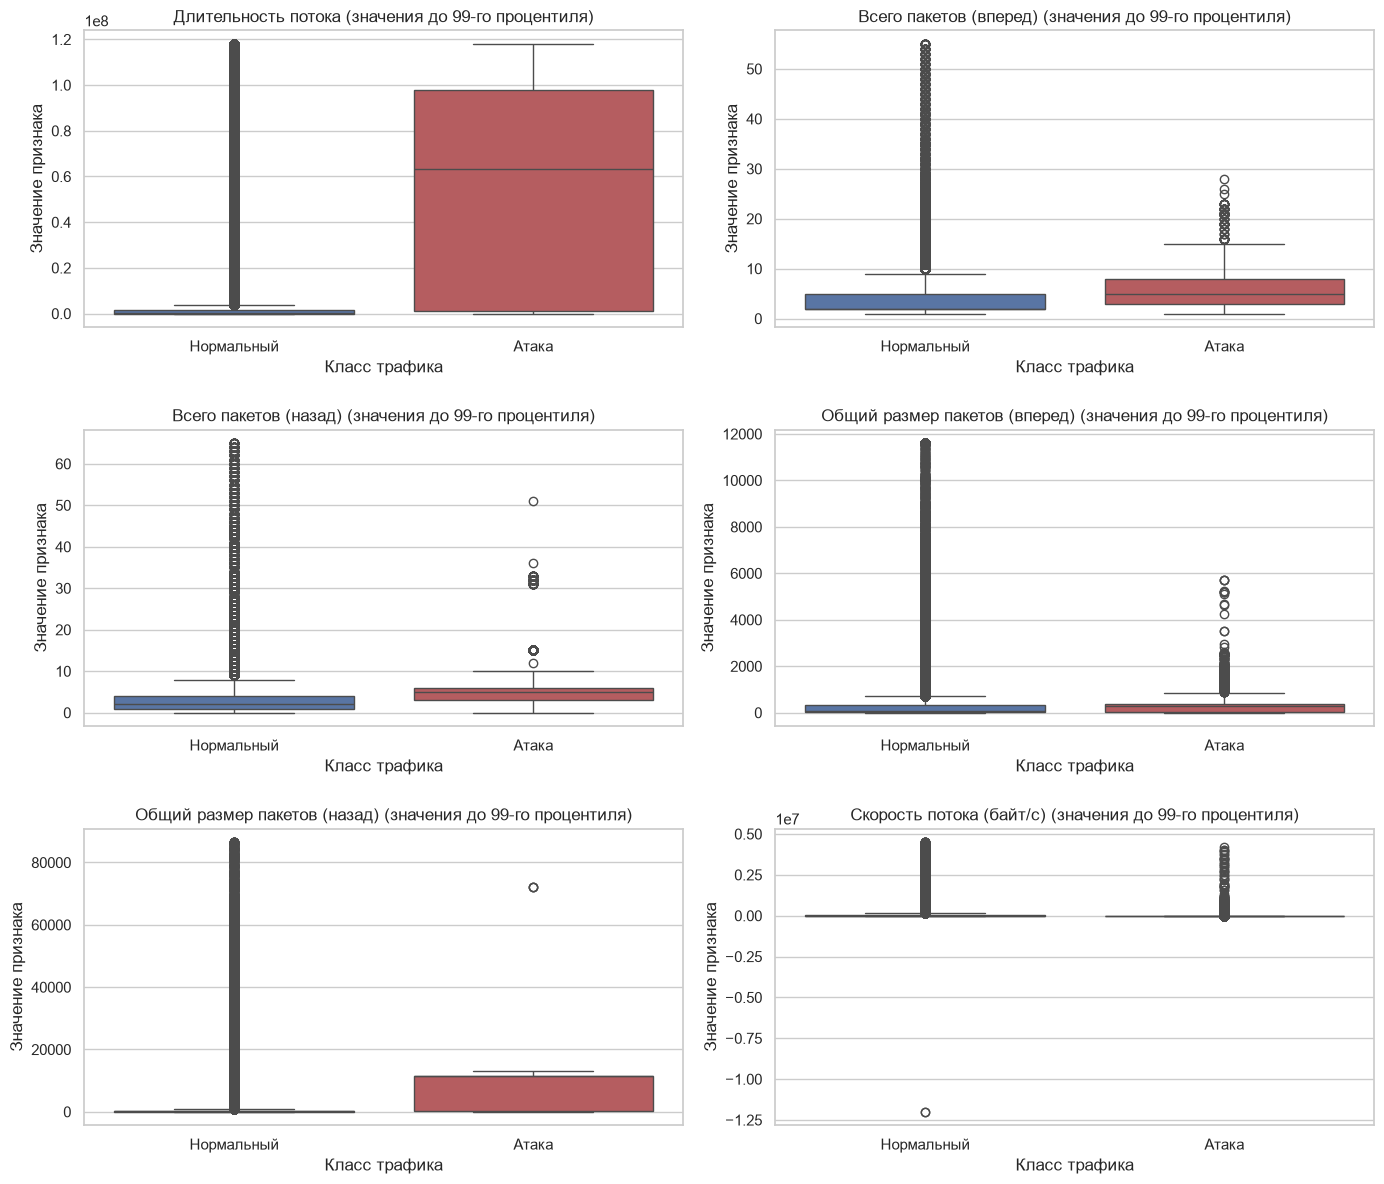

In [31]:
compare_features = available_features[:6]
plot_df = df[compare_features + ["target_ru"]].copy()

for col in compare_features:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

if compare_features:
    ncols = 2
    nrows = int(np.ceil(len(compare_features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, compare_features):
        temp = plot_df[[col, "target_ru"]].dropna()
        if len(temp) > 100_000:
            temp = temp.sample(100_000, random_state=RANDOM_STATE)
        if len(temp):
            upper = temp[col].quantile(0.99)
            temp = temp[temp[col] <= upper]
            
            sns.boxplot(data=temp, x="target_ru", y=col, ax=ax, palette=["#4c72b0", "#c44e52"])
            
            col_ru = FEATURE_TRANSLATIONS.get(col, col)
            ax.set_title(f"{col_ru} (значения до 99-го процентиля)")
            ax.set_xlabel("Класс трафика")
            ax.set_ylabel("Значение признака")

    for ax in axes[len(compare_features):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

**Комментарий к результатам.** Сравнение распределений между классами выявляет несколько закономерностей:
- ***Flow Duration*** — наиболее информативный признак: медиана у Attack (~6,3 × 10⁷ мкс) примерно на три порядка выше, чем у BENIGN (~10³ мкс). Распределение BENIGN сосредоточено у нуля, тогда как Attack занимает широкий диапазон. Признак потенциально хорошо разделяет классы, но требует логарифмирования из-за масштаба.

- ***Total Fwd Packets*** — распределения перекрываются существенно: у BENIGN медиана около 1–2 пакетов, у Attack — около 5. Атаки в среднем пакетированнее, но различие не абсолютное: часть нормального трафика тоже имеет 5–50 пакетов, а часть атак — 1–2. Признак информативен в комбинации с другими.

- ***Total Backward Packets*** — картина аналогична: медиана Attack (~3) выше, чем у BENIGN (~2), но распределения значительно перекрываются.

- ***Flow Bytes/s*** и ***Flow Packets/s*** — на графиках видны выраженные выбросы в обе стороны, включая отрицательные значения у BENIGN. Это следствие артефактов расчёта, а не реальных различий; после клиппинга отрицательных значений распределения станут чище. Содержательное различие: у Attack интенсивность в среднем выше, что соответствует сценариям DoS/DDoS.

**Практическое следствие:** признаки ***Flow Duration*** и интенсивности (***Flow Bytes/s***, ***Flow Packets/s***) являются наиболее перспективными для разделения классов. Признаки числа пакетов полезны в комбинации, но по отдельности слабы. Перед моделированием обязателен клиппинг отрицательных значений и логарифмирование для признаков с тяжёлыми хвостами.

## 16. Корреляционный анализ

Корреляционная матрица позволяет выявить сильно связанные признаки, что полезно при отборе признаков и интерпретации моделей. Для наглядности выбраны до 20 наиболее вариативных числовых признаков. Корреляция не означает причинно-следственной связи и не измеряет напрямую полезность признака для классификации.

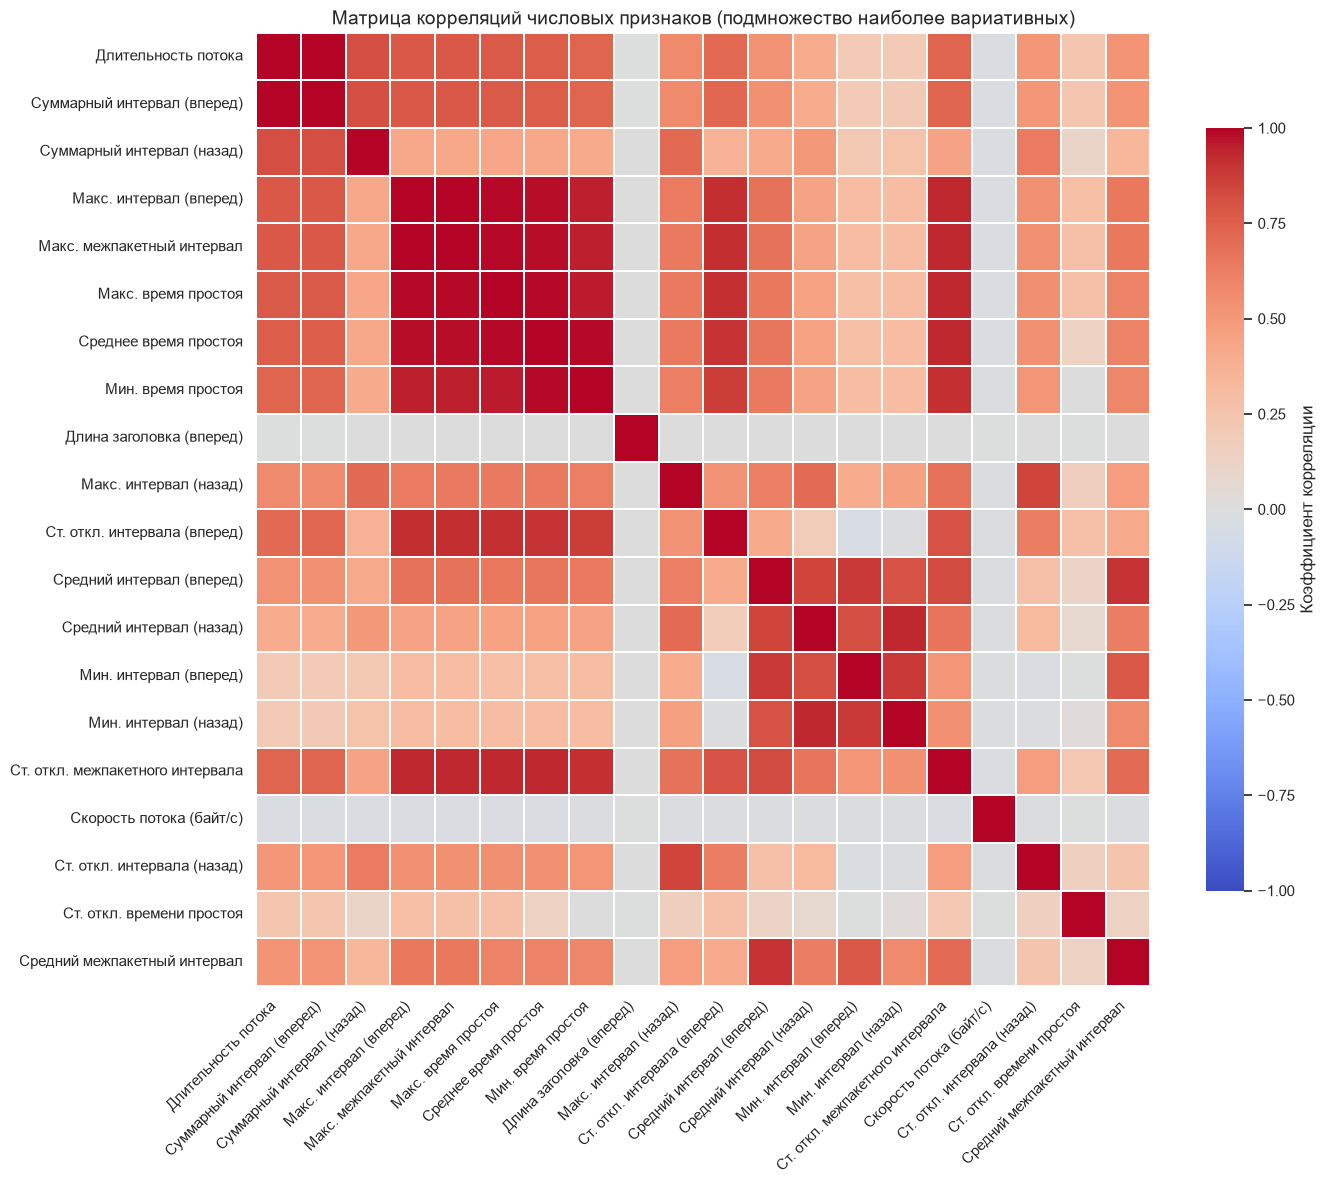

In [32]:
if len(numeric_features) >= 2:
    corr_source = df[numeric_features].replace([np.inf, -np.inf], np.nan)
    variances = corr_source.var(numeric_only=True).sort_values(ascending=False)
    selected_corr_features = variances.head(min(20, len(variances))).index.tolist()
    corr = corr_source[selected_corr_features].corr()

    translated_labels = [FEATURE_TRANSLATIONS.get(f, f) for f in selected_corr_features]
    
    plt.figure(figsize=(14, 12))
    sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
                linewidths=0.2, cbar_kws={"shrink": 0.8, "label": "Коэффициент корреляции"},
                xticklabels=translated_labels, yticklabels=translated_labels)
    
    plt.title("Матрица корреляций числовых признаков (подмножество наиболее вариативных)", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

**Комментарий к результатам.** Корреляционная матрица выявляет несколько групп сильно связанных признаков, что ожидаемо для CICFlowMeter, где многие признаки вычисляются как производные от одних и тех же величин.

**Блок почти идеальных корреляций (|r| > 0,95):**
- ***Fwd IAT Max*** ↔ ***Flow IAT Max*** ↔ ***Idle Max*** ↔ ***Idle Mean*** ↔ ***Idle Min*** — все описывают периоды простоя и максимальные межпакетные интервалы; фактически дублируют друг друга.

- ***Fwd IAT Mean*** ↔ ***Bwd IAT Mean*** ↔ ***Fwd IAT Min*** ↔ ***Bwd IAT Min*** — средние и минимальные межпакетные интервалы в обоих направлениях тесно связаны.

- ***Flow Duration*** ↔ ***Fwd IAT Total*** — длительность потока и суммарное время между прямыми пакетами практически совпадают.

- ***Fwd IAT Total*** ↔ ***Bwd IAT Total*** — суммарные времена в направлениях коррелируют сильно.

**Практическое следствие:**
1. Для линейных моделей (логистическая регрессия, SVM) набор признаков следует сократить, оставив по одному представителю из каждой сильно коррелированной группы — иначе мультиколлинеарность ухудшит обусловленность матрицы и стабильность коэффициентов.

2. Для древовидных моделей (Random Forest, Gradient Boosting) дублирующие признаки не критичны, но увеличивают размерность и время обучения; их удаление ускорит работу без потери качества.

3. При интерпретации feature importance коррелированные признаки «размывают» важность друг друга — это следует учитывать при анализе вклада признаков.

Признак ***Fwd Header Length*** и ***Flow Bytes/s*** слабо коррелируют с остальными — они могут нести независимую информацию, полезную для модели.

## 17. Проверка подозрительных значений и итоговая сводка

Для признаков, по смыслу неотрицательных (длительность, количество пакетов, объём данных), проверяется наличие отрицательных значений. Ниже также приведена сводная таблица основных характеристик набора.

In [ ]:
nonnegative_candidates = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Fwd Packets Length Total", "Bwd Packets Length Total",
]
for col in nonnegative_candidates:
    if col in df.columns:
        s = pd.to_numeric(df[col], errors="coerce")
        col_ru = FEATURE_TRANSLATIONS.get(col, col)
        print(f"{col_ru}: отрицательных = {(s < 0).sum():,}; NaN = {s.isna().sum():,}; inf = {np.isinf(s).sum():,}")

summary = {
    "Количество строк": len(df),
    "Количество столбцов": df.shape[1],
    "Количество числовых признаков": len(numeric_features),
    "Полные дубликаты (без source_file)": duplicate_count,
    "Пропущенные значения всего": int(df.isna().sum().sum()),
    "Доля нормального трафика (BENIGN), %": round(df["target_ru"].eq("Легитимный").mean() * 100, 2),
    "Доля атак (Attack), %": round(df["target_ru"].eq("Атака").mean() * 100, 2),
}

summary_df = pd.DataFrame(list(summary.items()), columns=["Показатель", "Значение"])
display(summary_df)

Длительность потока: отрицательных = 88; NaN = 0; inf = 0
Всего пакетов (вперед): отрицательных = 0; NaN = 0; inf = 0
Всего пакетов (назад): отрицательных = 0; NaN = 0; inf = 0
Общий размер пакетов (вперед): отрицательных = 0; NaN = 0; inf = 0
Общий размер пакетов (назад): отрицательных = 0; NaN = 0; inf = 0


,Показатель,Значение
0,Количество строк,2313810.00
1,Количество столбцов,81.00
2,Количество числовых признаков,77.00
3,Полные дубликаты (без source_file),82004.00
4,Пропущенные значения всего,0.00
5,"Доля нормального трафика (BENIGN), %",85.46
6,"Доля атак (Attack), %",14.54


**Комментарий к результатам.** Проверка подозрительных значений:
- ***Total Fwd Packets*** и ***Total Backward Packets*** — отрицательных значений нет, что ожидаемо (число пакетов не может быть отрицательным).

- ***Flow Duration*** — 88 отрицательных значений (минимум −13 мкс). Это артефакт вычисления, вероятно связанный с округлением временных меток; доля пренебрежимо мала (0,004 %), и такие строки можно безопасно отфильтровать или заменить на 0.

- ***Flow Bytes/s***, ***Flow Packets/s***, ***Flow IAT Mean***, ***Flow IAT Max***, ***Fwd IAT Min***, ***Fwd Header Length***, ***Bwd Header Length***, ***Fwd Seg Size Min***, ***Init Fwd Win Bytes***, ***Init Bwd Win Bytes*** — также содержат отрицательные значения. Для признаков Init ... Win Bytes значение -1 — стандартная семантическая метка «поле отсутствует», его замена нулём или удалением исказит данные; корректно оставить как есть либо ввести отдельный бинарный признак «поле отсутствует». Для производных интенсивностей и длин заголовков отрицательные значения — артефакты, их следует клиппировать в 0.

**Итоговая сводка набора**:

**1.** 2 313 810 строк × 80 столбцов (включая source_file и target_binary);

**2.** 77 числовых признаков;

**3.** 82 004 полных дубликата (3,54 %) — значимая доля, требующая удаления перед разбиением на train/test, чтобы избежать утечки;

**4.** пропущенных значений нет;

**5.** дисбаланс классов: BENIGN 85,46 % / Attack 14,54 %;

**6.** 8 сильно коррелированных групп признаков, 8 константных признаков (std = 0), отрицательные значения в 10+ признаках.

## 18. Выводы по результатам разведочного анализа

### 18.1. Характеристика набора данных
Объединённый набор содержит 2 313 810 записей из 8 Parquet-файлов, соответствующих сценариям CIC-IDS2017 по дням недели: Benign-Monday, Botnet-Friday, Bruteforce-Tuesday, DDoS-Friday, DoS-Wednesday, Infiltration-Thursday, Portscan-Friday, WebAttacks-Thursday. Исходная таблица содержит 77 числовых признаков и целевую метку Label. Общий объём Parquet-файлов — около 258 MiB, что соответствует полноценному набору для решения задачи бинарной классификации.

### 18.2. Качество данных
- Пропущенные значения: *отсутствуют во всех столбцах.*.
- Бесконечные значения: *отсутствуют*.
- Полные дубликаты: *82 004 строки (3,54 %) — требуют удаления перед разбиением на train/test.*.
- Отрицательные значения в неотрицательных по смыслу признаках: *присутствуют в 10+ признаках; для Flow Duration (88 строк) и производных интенсивностей это артефакты, для Init ... Win Bytes — семантическая метка «поле отсутствует».*.
- Константные признаки: *8 признаков (Bwd PSH Flags, Bwd URG Flags, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate) имеют нулевую дисперсию и подлежат удалению.*

### 18.3. Распределение классов
- Доля BENIGN: *85,46 % (1 977 318 записей)*; доля Attack: *14,54 % (336 492 записи)*.
- Класс атаки представлен в файлах: *DoS-Wednesday (193 756), DDoS-Friday (128 014), Bruteforce-Tuesday (9 150) и других; Infiltration-Thursday содержит только 36 атак (0,01 % от всех атак), что делает этот сценарий практически не представленным в выборке.*.
- Дисбаланс умеренный, но достаточный для отказа от accuracy как основной метрики.

### 18.4. Разделимость классов и информативность признаков
- Признаки, показавшие заметные различия между классами: *Flow Duration (медиана Attack на три порядка выше, чем у BENIGN), Flow Bytes/s и Flow Packets/s (интенсивность атак выше), Total Fwd/Backward Packets (умеренное различие).*.
- Признаки с выраженной асимметрией распределений: *Flow Duration, Total Fwd/Backward Packets, Flow Bytes/s, Flow Packets/s, Bwd Packets Length Total — все имеют длинные правые хвосты, требуют логарифмирования или клиппинга.*.
- Пары сильно коррелированных признаков: *IAT-признаки (Fwd IAT Max, Flow IAT Max, Idle Max/Mean/Min), временные суммы (Flow Duration, Fwd IAT Total, Bwd IAT Total), интервалы (Fwd IAT Mean/Min, Bwd IAT Mean/Min) — подлежат сокращению для линейных моделей.*.

### 18.5. Ограничения анализа
- Набор собран в лабораторной тестовой сети; реальный корпоративный трафик может отличаться по составу протоколов и интенсивности.
- Класс **Attack** объединён, что скрывает различия между типами атак и не позволяет оценить recall по каждой разновидности отдельно.
- Сценарная структура (привязка атак к конкретным файлам/дням) создаёт риск утечки при случайном разбиении.
- Результаты EDA не заменяют оценку качества модели на отложенных данных.

## 19. Рекомендации по предобработке

1. **Удалить константные признаки** (8 столбцов с std = 0) — они не несут информации.
2. **Удалить полные дубликаты** (82 004 строки, 3,54 %) до разбиения на train/test, чтобы избежать утечки.
3. **Обработать отрицательные значения:**
    - **Flow Duration** < 0 (88 строк) — заменить на 0 или отфильтровать;
    - **Flow Bytes/s**, **Flow Packets/s**, **Fwd/Bwd Header Length**, **Fwd Seg Size Min** — клиппировать в 0;
    - **Init Fwd/Bwd Win Bytes = −1** — оставить как семантическую метку или заменить на отдельный бинарный признак «поле отсутствует».
4. **Логарифмировать признаки с тяжёлыми хвостами** (log1p после клиппинга в 0): Flow Duration, Total Fwd/Backward Packets, Flow Bytes/s, Flow Packets/s, Bwd Packets Length Total. Для древовидных моделей логарифмирование не обязательно, но клиппинг нужен всегда.
5. **Сократить коррелированные группы для линейных моделей:** из каждой группы (IAT-признаки, временные суммы, интервалы) оставить один представитель. Для древовидных моделей можно оставить все — качество не пострадает, но обучение ускорится.
6. **Разбиение на train/test с учётом source_file (group split)** или по дням, чтобы избежать утечки между сценариями. Случайное разбиение недопустимо из-за сценарной структуры атак.
7. **Оценивать модель по precision, recall, F1 и PR-AUC для класса атак**. Accuracy использовать только справочно (наивный классификатор «всегда BENIGN» даст 85,46 % accuracy при нулевом recall).
## 20. Заключение

В ходе работы выполнен разведочный анализ набора CIC-IDS2017, представленного 8 Parquet-файлами общим объёмом 2 313 810 записей и 77 числовыми признаками. Установлено, что данные не содержат пропусков и бесконечностей, но включают 82 004 полных дубликата (3,54 %), 8 константных признаков, отрицательные артефакты в 10+ признаках и выраженную асимметрию распределений. Классы несбалансированы (85,46 % BENIGN / 14,54 % Attack), а класс атак имеет сценарную структуру: 95 % атак сосредоточено в четырёх файлах (DoS-Wednesday, DDoS-Friday, Bruteforce-Tuesday, Portscan-Friday), тогда как Infiltration-Thursday содержит лишь 36 атак.

Наиболее информативными для разделения классов оказались Flow Duration, Flow Bytes/s и Flow Packets/s; признаки числа пакетов полезны в комбинации. Выявлены 8 сильно коррелированных групп признаков, требующих сокращения для линейных моделей. Сформулированы рекомендации по предобработке: удаление дубликатов и констант, клиппинг отрицательных значений, логарифмирование асимметричных признаков, разбиение с учётом source_file и оценка по recall/precision/F1/PR-AUC для класса атак. Полученные результаты формируют обоснованную основу для следующего этапа — построения и валидации классификатора.